# 현실의 데이터 12: 부동산: 집값 예측

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/12_real_estate.ipynb)

**분야**: 도시 · 공간 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 부동산 시세 추정 · 공간 데이터 · 자동 가치 평가 (AVM)

> 캘리포니아 2만 640개 동네의 소득 · 방 수 · 위치. 이 동네 집값은 얼마일까?

**데이터**: California Housing (약 0.5MB). Pace & Barry (1997), 1990년 미국 인구조사의 캘리포니아 블록 그룹 20,640개: 소득 중앙값 · 집 나이 · 방 수 · 인구 · 위도 · 경도 → 집값 중앙값 (10만 달러 단위, 5.0 에서 잘림). scikit-learn 이 내려받는다.

인턴 · 산학협력 과제에서 처음 받게 될 데이터와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 동네 (블록 그룹) 하나 |
| ② 입력 X | 소득 · 집 나이 · 방 수 · 인구 · 위도 · 경도 |
| ③ 출력 y | 집값 중앙값 (10만 달러) |
| ④ 평가지표 | MAE (10만 달러) |
| ⑤ 기준선 | 전체 평균 집값 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Pace & Barry (1997) Sparse spatial autoregressions, Statistics & Probability Letters](https://doi.org/10.1016/S0167-7152(96)00140-X)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

In [2]:
from sklearn.datasets import fetch_california_housing
house = fetch_california_housing(as_frame=True, data_home="data")
df = house.frame
print(df.shape)
df.sample(5, random_state=0)

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
14740,4.1518,22.0,5.663073,1.075472,1551.0,4.180593,32.58,-117.05,1.369
10101,5.7796,32.0,6.107226,0.927739,1296.0,3.020979,33.92,-117.97,2.413
20566,4.3487,29.0,5.930712,1.026217,1554.0,2.910112,38.65,-121.84,2.007
2670,2.4511,37.0,4.992958,1.316901,390.0,2.746479,33.20,-115.60,0.725
15709,5.0049,25.0,4.319261,1.039578,649.0,1.712401,37.79,-122.43,4.600


## 열어 보기: 지도로 그리기

위도 · 경도로 점을 찍고 색 = 집값. 해안가 (샌프란시스코 · 로스앤젤레스) 가 비싸다. 집값 5.0 에 몰린 점들은 무엇일까?

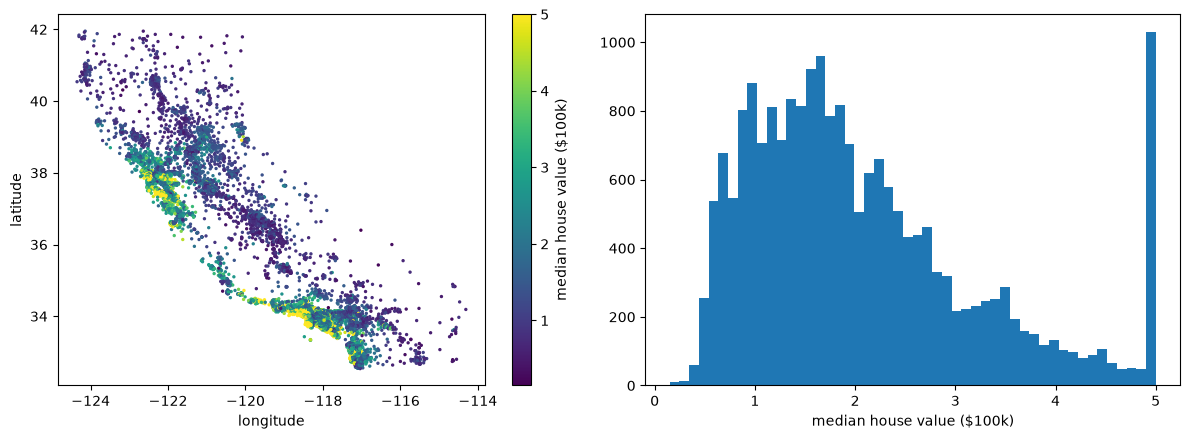

blocks at the cap 5.0: 992


In [3]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
sc = axs[0].scatter(df["Longitude"], df["Latitude"], c=df["MedHouseVal"], s=2, cmap="viridis")
plt.colorbar(sc, ax=axs[0], label="median house value ($100k)"); axs[0].set_xlabel("longitude"); axs[0].set_ylabel("latitude")
axs[1].hist(df["MedHouseVal"], bins=50); axs[1].set_xlabel("median house value ($100k)")
plt.tight_layout(); plt.show()
print("blocks at the cap 5.0:", (df["MedHouseVal"] >= 5.0).sum())

## 문제 하나 골라 보기: 동네 → 집값 (회귀)

**나누는 방법 두 가지** 를 비교한다.
- 무작위로 80 / 20
- **지역으로**: 경도 −121 보다 서쪽 (북부 해안) 을 시험으로. 모델이 '처음 보는 지역' 에서도 맞힐까?

In [4]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split

def mae(y_true, y_pred):
    return np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)))

X, y = df.drop(columns="MedHouseVal"), df["MedHouseVal"]
splits = {"random 80/20": train_test_split(X.index, test_size=0.2, random_state=0),
          "by region (west of -121 = test)": (X.index[X["Longitude"] >= -121], X.index[X["Longitude"] < -121])}
for name, (tr, te) in splits.items():
    m = HistGradientBoostingRegressor(random_state=0).fit(X.loc[tr], y.loc[tr])
    print(f"{name:32s} baseline MAE {mae(y.loc[te], np.full(len(te), y.loc[tr].mean())):.2f}   model MAE {mae(y.loc[te], m.predict(X.loc[te])):.2f}  (x $100k)")

random 80/20                     baseline MAE 0.91   model MAE 0.31  (x $100k)


by region (west of -121 = test)  baseline MAE 0.95   model MAE 0.78  (x $100k)


**관찰**: 무작위로 나누면 이웃 동네가 학습에 있어서 쉽다. 처음 보는 지역에서는 오차가 커진다. 부동산 · 지도 데이터는 **어떻게 나누느냐** 가 점수를 바꾼다.

## 다른 문제로 바꿔 보기

- 한국 아파트라면? 국토교통부 실거래가 (API 신청 필요): 한 행 = 거래 한 건, y = 거래 가격, 입력 = 면적 · 층 · 건축 연도 · 위치 · **거래 날짜**. 시간 순서로 나눠야 한다.
- 집값 5.0 에서 잘린 동네는 '5.0 이상' 이라는 뜻이다. 이걸 그대로 정답으로 쓰면 무엇이 문제일까?

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |